# import

In [58]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Environnement agent aléatoire

In [59]:
env = gym.make("LunarLander-v3")

#récupération de l'environnement et des actions
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

# print(state_dim)
# print(action_dim)

# Test de l'agent aléatoire
state, info = env.reset(seed=42)
total_reward = 0.0
done = False
steps = 0

while not done:
    # l'agent choisit une action au hasard
    action = env.action_space.sample()
    
    # on applique l'action
    next_state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    steps += 1
    
    # l'épisode est fini si le vaisseau s'écrase, atterrit terminated ou atteint la limite de temps truncated
    done = terminated or truncated

print(f"Score de l'agent aléatoire : {total_reward:.1f} (en {steps} étapes)")
env.close()



Score de l'agent aléatoire : -223.1 (en 125 étapes)


# Actor/Critic initialisation

In [60]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(ActorCritic, self).__init__()


        # ce réseau va permettre de donner une probabiltié de la prochaine action a réaliser selon l'env du vaisseau
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 64), # prend nos 8 valeurs d'entrées et les envoie dans une couche de 64 neuronnes
            nn.Tanh(), # convertit nos donneés entre -1 et 1 pour une meilleur exploitation 
            nn.Linear(64, 64), # on refournit nos données déjà entrainé sur nos 64 neuronnes dnas 64 nouveaux neurones une couche de plus
            nn.Tanh(),
            nn.Linear(64, action_dim) # output des 4 actions
        )
        
        # sort une seule valeur estimation de l'action
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1) 
        )
        

    #  cet fonction permet de choisir le chemin que la donnée va suivre dans notre réseau de neuronne
    def forward(self, state):
        action_probs = self.actor(state)
        state_value = self.critic(state)
        return action_probs, state_value


# Rollout buffer

In [61]:
class RolloutBuffer:
    def __init__(self):

        #données de l'environnement
        self.states =[]
        self.actions=[]
        self.rewards= []
        self.is_terminals= []

        # nous indiquera a quel point la politique a changé
        # si par exemple après l'action il est sur a 80% de l'action faites, on comparera avec a quel point il est sur apres mise a jour de la politique genre si 90%
        # on fera 90/80 qui donnera 1.125 donc une estimation de a quel point la politique a changé
        self.certitude= []

        # sauvegarde du v(s) du critique au moment de l'action
        self.state_values= []


    def clear(self):

        del self.states[:]
        del self.actions[:]
        del self.rewards[:]
        del self.is_terminals[:]
        del self.certitude[:]
        del self.state_values[:]

buffer = RolloutBuffer()




# GAE

il permet de calculer si l'action c'est révélée meilleur ou pire que ce que le critique avait prédit

In [ ]:
#  gamma indique que l'agent doit valoriser les récompenses futures presque autant que les récompenses immédiates
#   gae lambda va permettre de stabiliser lentrainement
def compute_gae(buffer, gamma=0.99, gae_lambda=0.98):

    advantages = [] # *on va ranger la note finale de chaque action + ou -
    returns = []    #  on va ranger le score réel total de l'action
    gae = 0   

    for step in reversed(range(len(buffer.rewards))):
        is_terminal = buffer.is_terminals[step] # on observe si le vaisseau a termné l'action, crashé ou pas

        if step == len(buffer.rewards) -1 or is_terminal: # si on est l'index de la fin des éléments ou que l'action est terminée
            next_value = 0 # il n'a donc plus de donneés ou c'est arreté donc plus d'état suivant, on fixe alors la valeur a 0
        else:
            # si on est pas au derniere éléments ou que l'acction n'est pas terminé alors on est en plein vol ou pleine action du vaisseau 
            # on récupère alors la valeurs que le critique nous renvoie 
            # sans .item on aurait une donnée tensor illisible donc on item pour avori un chiffre basique
            next_value = buffer.state_values[step + 1].item()

        # on récupère l'ancienne valeur du critique
        current_value = buffer.state_values[step].item()

        # si next_value est plus grand que current value alors on considère que l'action faite dans le futur est meilleur que celle du passé

        # CALCULE DE LA SURPRISE -> décalage entre l'estimation du critique et la vérité 
        # delta prend la récompense immédiate
        delta = buffer.rewards[step] + gamma * next_value - current_value

        # gae prend lisse les résultats pour avoir une estimation de la précision du critique général
        
        # vérification, si la parti est terminé on remet notre gae a 0
        if is_terminal:
            gae = 0
            
        # surprise immédiate + ce qui se passe dans le futur
        # imagine que sur un instant T on coupe le moteur, l'ia va dire "cool on économise du carburant + 5 récompenses" mais
        # sur le futur ca va litéralement tuer la trajectoire et il se crash, donc l'action a l'instant T est bonne mais par 
        # la suite on doit prendre en compte le fait vaisseau se crash.
        gae = delta + gamma * gae_lambda * gae


        
        advantages.insert(0,gae)

        # return correspond à notre prédiction du critique + le bonus ou malus de l'action 
        returns.insert(0,gae+ current_value)
    return advantages ,returns

# PPO initialisation -> injection de l'actor/critique

In [63]:
class PPOAgent:
    def __init__(self, state_dim,action_dim, lr= 0.0003): # convention d'apprentissage classique - si trop petit alors on aurait besoin de 10k d'épisodes
        self.policy = ActorCritic(state_dim, action_dim).to(device)

        #optimiseur
        self.optimizer = optim.Adam(self.policy.parameters(), lr=lr)

    def select_action(self, state, buffer):
        #conversion de notre environnement en tensor pytorch exploitable
        state = torch.FloatTensor(state).to(device)

        with torch.no_grad():
            action_probs, state_value = self.policy(state)


        # instancier les probabilités choisies par le modèle 
        dist = Categorical(logits=action_probs)

        # va permettre de choisir l'action selon les probabilités renvoyés 
        # genre si on a 0.1 0.5 0.2 0.2 ya 50% de chance que le modele choisisse l'action 2 
        action = dist.sample()


        # remplir le buffer
        buffer.states.append(state)
        buffer.actions.append(action)
        buffer.certitude.append(dist.log_prob(action))
        buffer.state_values.append(state_value)

        return action.item()

    def update(self, buffer, epochs=10, batch_size=64, epsilon=0.2): # epochs -> révision sur le meme buffer, batch_size -> paquets de step sur lequels ils s'entrainent
        # epsilon -> clipping du modèle, lempeche de changer brutalement de politique si il trouve une super action 
        
        # récupération et transformation en tensor de l'action précédentes
        old_states = torch.squeeze(torch.stack(buffer.states, dim=0)).detach().to(device)
        old_actions = torch.squeeze(torch.stack(buffer.actions, dim=0)).detach().to(device)
        old_logprobs = torch.squeeze(torch.stack(buffer.certitude, dim=0)).detach().to(device)

        advantages, returns = compute_gae(buffer)
        advantages = torch.tensor(advantages, dtype=torch.float32).to(device)
        returns = torch.tensor(returns, dtype=torch.float32).to(device)

        buffer_size = len(buffer.states)
        indices = np.arange(buffer_size)

        # 2. Boucle d'entrainement par mini-batch
        for _ in range(epochs):
            np.random.shuffle(indices) # melanger les données
            
            for start in range(0, buffer_size, batch_size):
                end = start + batch_size
                mb_indices = indices[start:end] # va contenir donc un petit paquet de 64 états

                # Extraction des différentes data des 64 états
                mb_states = old_states[mb_indices]
                mb_actions = old_actions[mb_indices] # 0 1 2 3
                mb_logprobs = old_logprobs[mb_indices] # cest la certitude du critique AU MOMENT DE L'ACTION
                mb_advantages = advantages[mb_indices]
                mb_returns = returns[mb_indices]
                
                action_logits, state_values = self.policy(mb_states)
                
                dist = Categorical(logits=action_logits) 
                certitude = dist.log_prob(mb_actions) # nouvelle évaluation du critique apres maj de politique  
                entropy = dist.entropy().mean() # calcule de son hésitation
                
                ratios = torch.exp(certitude - mb_logprobs) # on compare le niveua de confiance actuel de celui du passé
                # ratios va nous donner grâce a .exp un chiffre clair de si notre politique est meilleur ou non.

                # Calcul des pertes

                # on ajoute le bonus ou le malus de la nouvelle acction
                scorebrut = ratios * mb_advantages 

                # calcule qui permet de gérer au cas ou si un ratio rendrait notre modele dégéneratif et voudrait spammer une action si elle est trop récompensé
                # on ajoute l'epsilone pour brider un ratio 
                scorebrut_sécu = torch.clamp(ratios, 1 - epsilon, 1 + epsilon) * mb_advantages

                # permet de choisir la valeur la plus basse, on part du principe que si l'ia veut faire un trop gros changement, cest qu'elle a faux
                actor_loss = -torch.min(scorebrut, scorebrut_sécu).mean()

                # calcule de la perte, pénalise les énormes erreurs
                critic_loss = nn.MSELoss()(state_values.squeeze(-1), mb_returns)

                # maj des poids
                
                # supprimez lesx anciens calcules dans la mémoire
                self.optimizer.zero_grad()
                #  note final des erreurs de notre modèle
                # actor_loss correspnd donc a la mauvaise conduite du vaisseau, on multiplie par la loss pour éviter d'afoler le modèle et qu'il ne veuille que 
                # améliorer le critique, il faut d'abord qu'il puisse bien mener le vaisseau
                # on récuompense aussi le réseau tres legerement si il hésite entre les décisions avec entropy. ca évite qu'il puisse parfois s'enfermer
                loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy

                # backward va permettre dans des .grad de stocker la loss de cahque neurones, cest a dire si un neurone à +2 par exemple
                # l'optimizer ne va pas aumgneter le poid de ce neuronne a l'inverse si
                loss.backward()

                # entrainement la modification du réseau
                self.optimizer.step()

        return actor_loss.item(), critic_loss.item(), entropy.item()


#vérifictation de la compilation de l'agent
ppo_agent = PPOAgent(state_dim, action_dim)

# Entrainement

In [64]:
max_episodes = 1500
scores = [] #progression

# listes pour les observations
raisons_fin_ppo = {"truncated": 0, "out_of_viewport": 0, "at_rest": 0, "crash": 0}
episodes_lengths = []
policy_losses = []
value_losses = []
entropies = []


for episode in range(max_episodes):

    state, info = env.reset()
    total_reward = 0
    done = False
    steps = 0 

    while not done:
        # selection de l'agent ppo qui choisi l'action selon l'environement et les datas dans le buffer
        action = ppo_agent.select_action(state,buffer)

        next_state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated
        steps += 1   

        buffer.rewards.append(reward)
        buffer.is_terminals.append(done)

        total_reward += reward   # on accumule les points
        state = next_state       # le vaisseau avance dans le temps


    scores.append(total_reward)
    episodes_lengths.append(steps)
    
    # Statistiques de fin
    if truncated:
        raisons_fin_ppo["truncated"] += 1
    elif reward == 100:
        raisons_fin_ppo["at_rest"] += 1
    elif abs(next_state[0]) >= 1.0:
        raisons_fin_ppo["out_of_viewport"] += 1
    else:
        raisons_fin_ppo["crash"] += 1
    
    # on ne fait l'update que tous les 5 épisodes pour accumuler assez de données
    if (episode + 1) % 5 == 0:
        a_loss, c_loss, ent = ppo_agent.update(buffer) 
        policy_losses.append(a_loss)                   
        value_losses.append(c_loss)
        entropies.append(ent)
        
        buffer.clear()


    if (episode + 1) % 10 == 0:
            moyenne_recente = np.mean(scores[-10:])
            moyenne_globale = np.mean(scores)
            print(f"Épisode {episode + 1} | Score moyen récent : {moyenne_recente:.1f} | Score moyen global : {moyenne_globale:.1f}")

Épisode 10 | Score moyen récent : -177.6 | Score moyen global : -177.6
Épisode 20 | Score moyen récent : -133.7 | Score moyen global : -155.7
Épisode 30 | Score moyen récent : -229.8 | Score moyen global : -180.4
Épisode 40 | Score moyen récent : -229.5 | Score moyen global : -192.7
Épisode 50 | Score moyen récent : -224.6 | Score moyen global : -199.1
Épisode 60 | Score moyen récent : -202.9 | Score moyen global : -199.7
Épisode 70 | Score moyen récent : -154.8 | Score moyen global : -193.3
Épisode 80 | Score moyen récent : -139.5 | Score moyen global : -186.6
Épisode 90 | Score moyen récent : -181.1 | Score moyen global : -185.9
Épisode 100 | Score moyen récent : -123.2 | Score moyen global : -179.7
Épisode 110 | Score moyen récent : -221.1 | Score moyen global : -183.4
Épisode 120 | Score moyen récent : -189.1 | Score moyen global : -183.9
Épisode 130 | Score moyen récent : -176.8 | Score moyen global : -183.4
Épisode 140 | Score moyen récent : -170.0 | Score moyen global : -182.4
É

# Sauvegarde du modèle

In [65]:
torch.save(ppo_agent, "lunarlander_ppo.pth")

print("Modèle sauvegardé !")

Modèle sauvegardé !


# Graphiques des résultats de l'entraînement

## Observation de l'apprensitage du modèle PPO

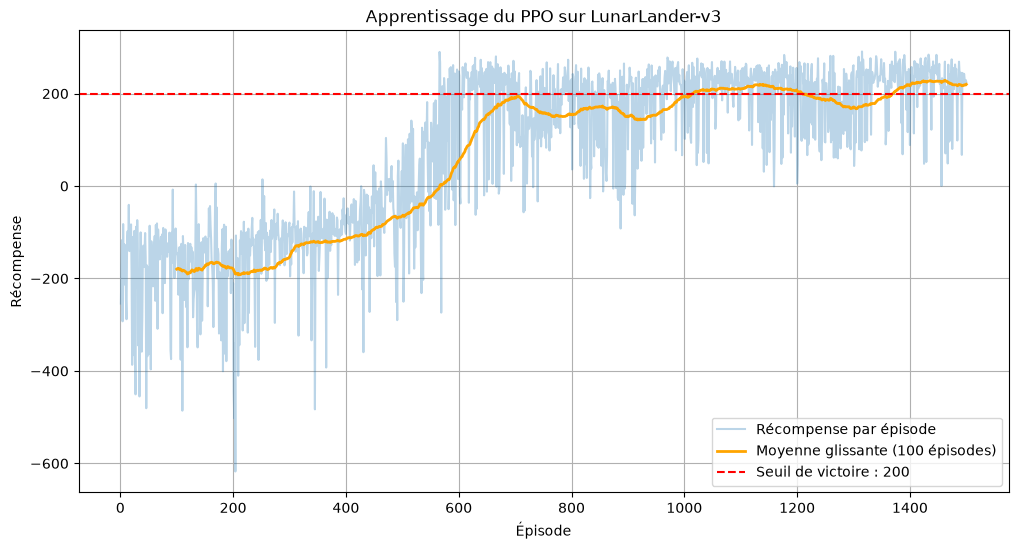

In [66]:
rewards = scores 
episodes = list(range(1, len(scores) + 1))

moving_average = np.convolve(rewards, np.ones(100) / 100, mode="valid")
plt.figure(figsize=(12, 6))

plt.plot(episodes, rewards, alpha=0.3, label="Récompense par épisode")
plt.plot(episodes[100 - 1:], moving_average, label="Moyenne glissante (100 épisodes)", color="orange", linewidth=2)

plt.axhline(y=200, color="red", linestyle="--", label="Seuil de victoire : 200")
plt.xlabel("Épisode")
plt.ylabel("Récompense")
plt.title("Apprentissage du PPO sur LunarLander-v3") 
plt.legend()

plt.grid(True)
plt.show()

## Statistiques de terminaison et Longueur des épisodes


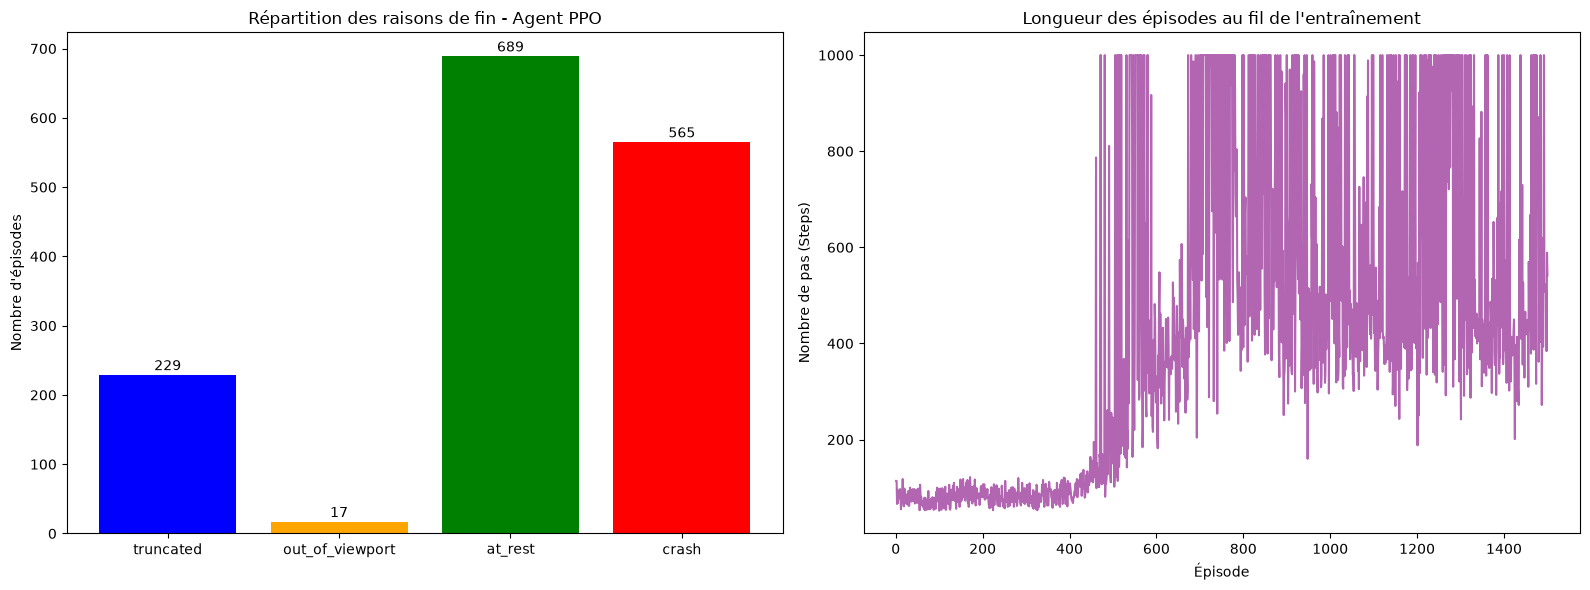

In [67]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Raisons de fin d'épisode
raisons = list(raisons_fin_ppo.keys())
nombres = list(raisons_fin_ppo.values())
ax1.bar(raisons, nombres, color=['blue', 'orange', 'green', 'red'])
ax1.set_title("Répartition des raisons de fin - Agent PPO")
ax1.set_ylabel("Nombre d'épisodes")
for i, v in enumerate(nombres):
    ax1.text(i, v + 2, str(v), ha='center', va='bottom')

# Graphique 2 : Longueur des épisodes
ax2.plot(range(1, len(episodes_lengths) + 1), episodes_lengths, color='purple', alpha=0.6)
ax2.set_title("Longueur des épisodes au fil de l'entraînement")
ax2.set_xlabel("Épisode")
ax2.set_ylabel("Nombre de pas (Steps)")

plt.tight_layout()
plt.show()

## Les courbes de pertes (Policy Loss, Value Loss) et d'Entropie.

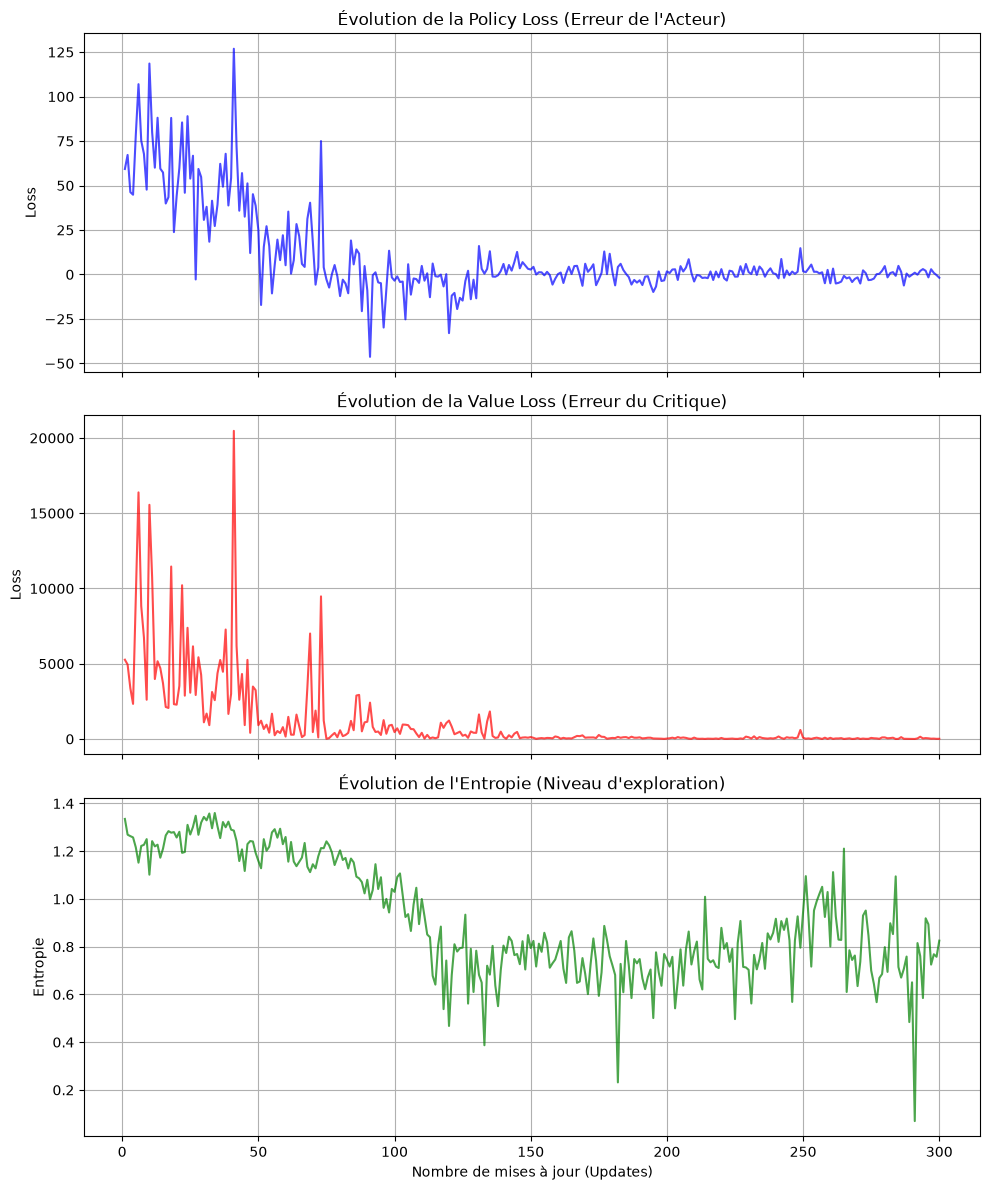

In [68]:
# Création d'un axe des X correspondant au nombre de mises à jour
updates = range(1, len(policy_losses) + 1)

# Création d'une figure avec 3 graphiques empilés
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

# 1. Graphique de la Policy Loss (Acteur)
ax1.plot(updates, policy_losses, color='blue', alpha=0.7)
ax1.set_title("Évolution de la Policy Loss (Erreur de l'Acteur)")
ax1.set_ylabel("Loss")
ax1.grid(True)

# 2. Graphique de la Value Loss (Critique)
ax2.plot(updates, value_losses, color='red', alpha=0.7)
ax2.set_title("Évolution de la Value Loss (Erreur du Critique)")
ax2.set_ylabel("Loss")
ax2.grid(True)

# 3. Graphique de l'Entropie
ax3.plot(updates, entropies, color='green', alpha=0.7)
ax3.set_title("Évolution de l'Entropie (Niveau d'exploration)")
ax3.set_xlabel("Nombre de mises à jour (Updates)")
ax3.set_ylabel("Entropie")
ax3.grid(True)

plt.tight_layout()
plt.show()

## L'évaluation sur 100 épisodes

Début de l'évaluation sur 100 épisodes...

--- RÉSULTATS DE L'ÉVALUATION ---
Score moyen sur 100 épisodes : 219.40 ± 49.58


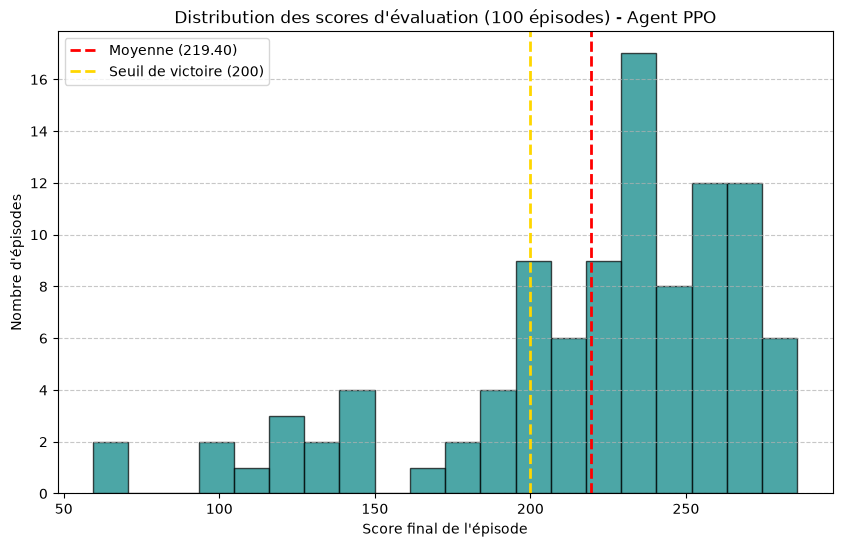

In [ ]:

eval_scores = []
env_eval = gym.make("LunarLander-v3")

# On passe le modèle en mode évaluation (bonne pratique PyTorch)
ppo_agent.policy.eval()

print("Début de l'évaluation sur 100 épisodes...")

for i in range(1, 101):
    state, _ = env_eval.reset(seed=42+i) # Une seed différente par épisode pour varier les situations
    done = False
    score = 0
    
    while not done:
        # On convertit l'état en tenseur comme dans l'entraînement
        state_tensor = torch.FloatTensor(state).to(device)
        
        with torch.no_grad():
            # Action gloutonne (exploitation pure) : on prend la plus forte probabilité
            action_logits, _ = ppo_agent.policy(state_tensor)
            action = action_logits.argmax().item()
            
        next_state, reward, terminated, truncated, _ = env_eval.step(action)
        done = terminated or truncated
        score += reward
        state = next_state
        
    eval_scores.append(score)

env_eval.close()

# Calcul des statistiques exigées par le sujet
mean_score = np.mean(eval_scores)
std_score = np.std(eval_scores)

print(f"\n--- RÉSULTATS DE L'ÉVALUATION ---")
print(f"Score moyen sur 100 épisodes : {mean_score:.2f}")

# --- CRÉATION DE L'HISTOGRAMME DE DISTRIBUTION ---
plt.figure(figsize=(10, 6))
plt.hist(eval_scores, bins=20, color='teal', edgecolor='black', alpha=0.7)

# Lignes indicatives pour la moyenne et le seuil de victoire
plt.axvline(mean_score, color='red', linestyle='dashed', linewidth=2, label=f'Moyenne ({mean_score:.2f})')
plt.axvline(200, color='gold', linestyle='dashed', linewidth=2, label='Seuil de victoire (200)')

plt.title("Distribution des scores d'évaluation (100 épisodes) - Agent PPO")
plt.xlabel("Score final de l'épisode")
plt.ylabel("Nombre d'épisodes")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()